# EVCharge Intelligence — plotting code and inline charts

Member 2: **Sagar K, PES2UG24CS424**. This companion notebook shows the code behind the temporal visualizations and embeds actual chart outputs. It recalculates and validates through `demand_analysis.py`, compares against the verified Phase 2 summaries, and draws from those summaries. No saved chart images are read or written.

Research motivation: Baek, K., Lee, E., & Kim, J. (2024), [*A dataset for multi-faceted analysis of electric vehicle charging transactions*](https://doi.org/10.1038/s41597-024-02942-9), Scientific Data, 11, 262. Temporal inspection is a methodological idea; the paper's dataset and results are separate from ours. Session starts differ from connection/coupling profiles; calendar normalization and our index are project choices.

Source: generated synthetic Indian charging data. Timezone is Asia/Kolkata; generator code, seed, sampling/loss assumptions and reuse licence were not supplied.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display

current = Path.cwd().resolve()
ROOT = current if (current / "src/demand_analysis.py").is_file() else current.parent
if not (ROOT / "src/demand_analysis.py").is_file():
    raise RuntimeError("Run from the repository root or notebooks directory.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.data_preparation import file_hash
from src.demand_analysis import analyze_sessions, WEEKDAYS, LOCATION_TYPES, CHARGER_TYPES, sensitivity_has_variation
from src.demand_visualization import (
    load_analysis, style_axis, finish_figure, month_ticks,
    BLUE, ORANGE, GREEN, ENERGY_NOTE,
)

# Activate inline rendering after imports; the reusable CLI module uses Agg.
%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import Patch
from matplotlib_inline.backend_inline import set_matplotlib_formats
import seaborn as sns

set_matplotlib_formats("png")  # One normal-resolution output, without retina/SVG duplicates.
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 110, "font.size": 10,
                     "axes.titlesize": 12, "font.family": "DejaVu Sans"})
sns.set_style("white")

summary_dir = ROOT / "outputs/demand"
protected = [ROOT / "data/processed/charging_sessions.csv",
             *sorted(summary_dir.glob("*.csv")), summary_dir / "analysis_summary.json"]
protected_hashes = {path: file_hash(path) for path in protected}
tables, summary = load_analysis(summary_dir)
cleaned = pd.read_csv(protected[0], dtype=str, keep_default_na=False)
recomputed_tables, recomputed_summary = analyze_sessions(cleaned)
for name, saved_table in tables.items():
    pd.testing.assert_frame_equal(saved_table, recomputed_tables[name],
                                  check_dtype=False, rtol=1e-10, atol=1e-6)
assert recomputed_summary["reconciliation"]["all_passed"]
del cleaned, recomputed_tables
print(f"Validated {summary['input_session_count']:,} sessions and all summary tables.")


def show_inline(figure, note):
    """Reuse layout helpers, display once, then close to prevent duplicate outputs."""
    try:
        finish_figure(figure, note)
        display(figure)
    finally:
        plt.close(figure)

Validated 200,000 sessions and all summary tables.


## 1. Hourly starts

**Question:** Do session starts concentrate in particular hours? **Metric:** average session starts per calendar day in each start hour. All 24 hours use the same 730-date denominator. The dashed reference is the mean of the 24 hourly averages; labels report extreme ties without changing the zero-based scale.

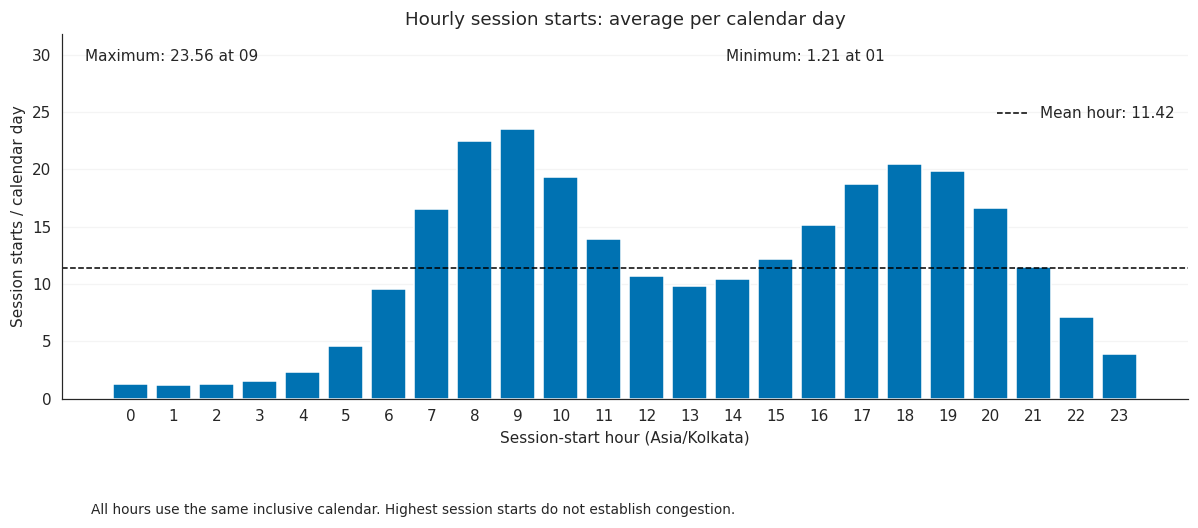

In [2]:
hourly = tables["hourly_demand"]
fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(hourly.Charging_Hour, hourly.avg_sessions_per_day, color=BLUE)
mean_hour = hourly.avg_sessions_per_day.mean()
ax.axhline(mean_hour, color="black", linestyle="--", linewidth=1,
           label=f"Mean hour: {mean_hour:.2f}")
for label, value, position in [
    ("Maximum", hourly.avg_sessions_per_day.max(), 0.02),
    ("Minimum", hourly.avg_sessions_per_day.min(), 0.59),
]:
    tied_hours = hourly.loc[hourly.avg_sessions_per_day.eq(value), "Charging_Hour"]
    hours_text = ", ".join(f"{hour:02d}" for hour in tied_hours)
    ax.text(position, 0.96, f"{label}: {value:.2f} at {hours_text}",
            transform=ax.transAxes, va="top")
ax.set_xticks(range(24))
ax.set_ylim(0, hourly.avg_sessions_per_day.max() * 1.35)
ax.set_xlabel("Session-start hour (Asia/Kolkata)")
ax.set_title("Hourly session starts: average per calendar day")
style_axis(ax, "Session starts / calendar day")
ax.legend(frameon=False, loc="upper right", bbox_to_anchor=(1, 0.84))
show_inline(fig, "All hours use the same inclusive calendar. Highest session starts do not establish congestion.")

**Findings and limitations:** Hourly demand is no longer nearly uniform: relative index 0.10560–2.06376. Hour 09 has the most starts (17,198; 23.56/calendar day), versus hour 01 (880; 1.21/day). This is the generated sample's pattern, not evidence of real congestion or actual Indian charging behavior.

## 2. Daily starts and smoothing

**Question:** How does recorded daily demand vary over the calendar? **Metric:** session starts/date and a trailing 7-day mean. The existing analysis supplies every date, including zero-session dates. Smoothing requires seven observations (`min_periods=7`); the initial six means remain missing.

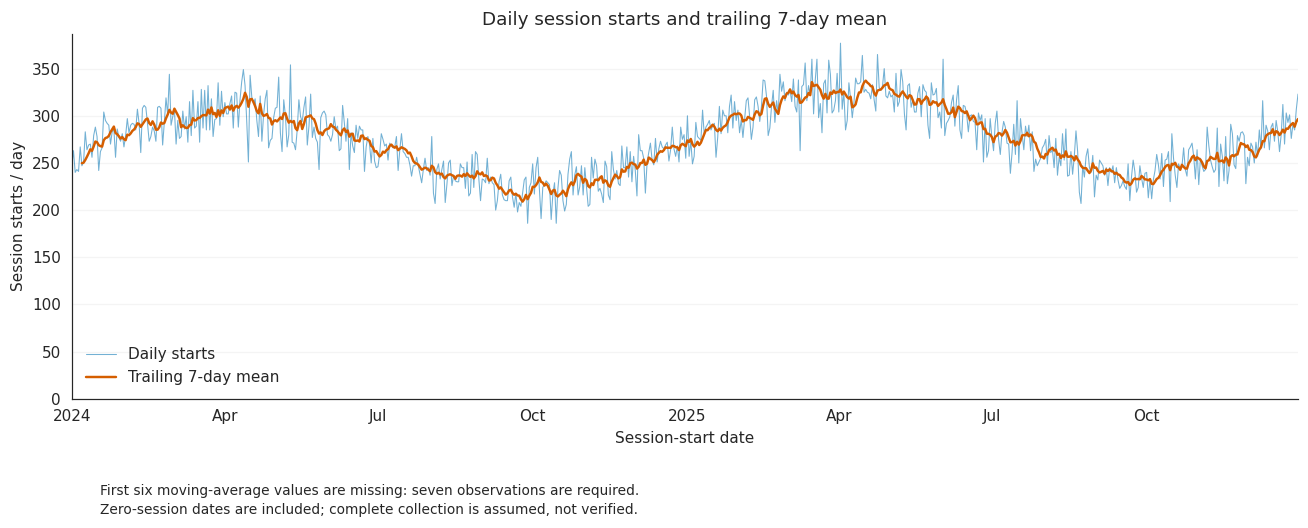

In [3]:
daily = tables["daily_demand"]
dates = pd.to_datetime(daily.Charging_Date, format="%Y-%m-%d")
# This is display smoothing of an existing summary, not session aggregation.
trailing_mean = daily.session_count.rolling(window=7, min_periods=7).mean()
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(dates, daily.session_count, color=BLUE, linewidth=0.7, alpha=0.55,
        label="Daily starts")
ax.plot(dates, trailing_mean, color=ORANGE, linewidth=1.6, label="Trailing 7-day mean")
locator = mdates.AutoDateLocator(minticks=5, maxticks=9)
ax.xaxis.set_major_locator(locator)
ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
ax.set_xlim(dates.min(), dates.max())
ax.set_xlabel("Session-start date")
ax.set_title("Daily session starts and trailing 7-day mean")
style_axis(ax, "Session starts / day")
ax.legend(frameon=False, loc="lower left")
show_inline(fig, "First six moving-average values are missing: seven observations are required.\nZero-session dates are included; complete collection is assumed, not verified.")

**Findings and limitations:** Daily starts peak at 377 on 2025-04-02 and are lowest at 186 on 2024-09-28, 2024-10-15. The trailing 7-day mean requires seven observations; the first six values remain missing.

## 3. Weekdays and weekends

**Question:** Do average starts differ across calendar day types? **Metric:** starts divided by the number of dates belonging to each weekday or weekday/weekend group, not by all dates.

For example, three starts across two Fridays yield 1.5/Friday, while two starts on one Saturday yield 2/Saturday. Raw totals alone obscure unequal coverage. Both panels use the same vertical scale.

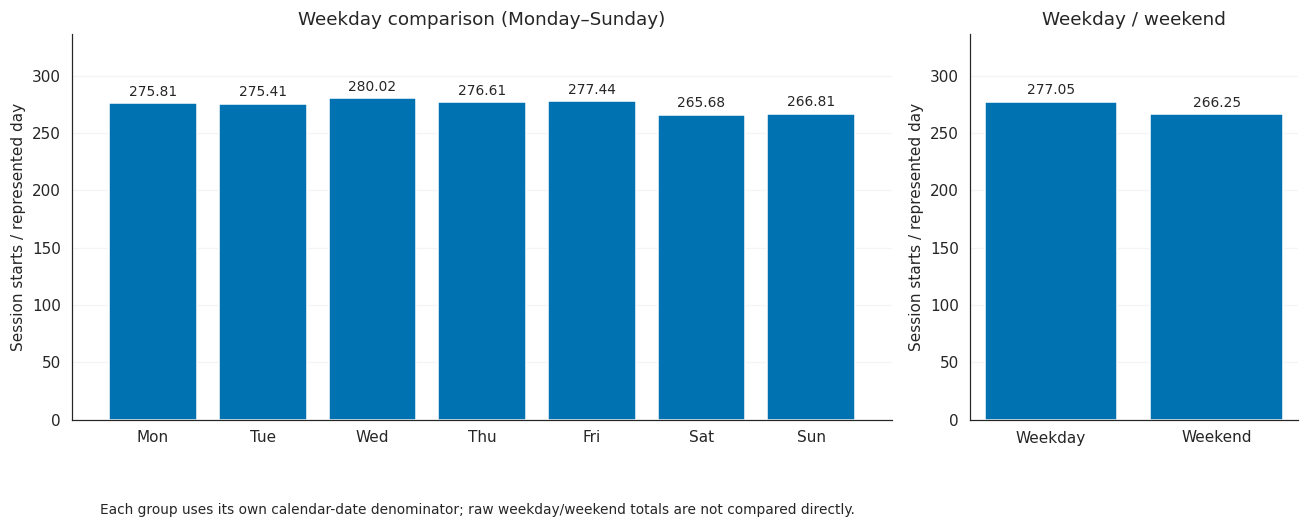

In [4]:
weekday = tables["weekday_demand"]
weekend = tables["weekday_weekend_demand"]
fig, axes = plt.subplots(1, 2, figsize=(12, 5), gridspec_kw={"width_ratios": [2.5, 1]})
for ax, group, labels in [
    (axes[0], weekday, weekday.Weekday_Name.str[:3]),
    (axes[1], weekend, weekend.Day_Type),
]:
    bars = ax.bar(labels, group.avg_sessions_per_day, color=BLUE)
    ax.bar_label(bars, fmt="%.2f", padding=3, fontsize=9)
    style_axis(ax, "Session starts / represented day")
ceiling = max(weekday.avg_sessions_per_day.max(), weekend.avg_sessions_per_day.max()) * 1.2
for ax in axes:
    ax.set_ylim(0, ceiling)
axes[0].set_title("Weekday comparison (Monday–Sunday)")
axes[1].set_title("Weekday / weekend")
show_inline(fig, "Each group uses its own calendar-date denominator; raw weekday/weekend totals are not compared directly.")

**Findings and limitations:** Weekdays average 277.05 starts/day across 522 dates; weekends average 266.25 across 208 dates. Wednesday is highest (280.02/day); Saturday is lowest (265.68/day). Comparisons use each group's calendar denominator; no significance or causes are inferred.

## 4. Weekday–hour demand

**Question:** Is there a distinct day–hour concentration of starts? **Metric:** average starts in a weekday–hour cell divided by the number of that weekday's dates. Reshape the verified 168-row table without aggregating sessions again. A sequential color scale starts at zero.

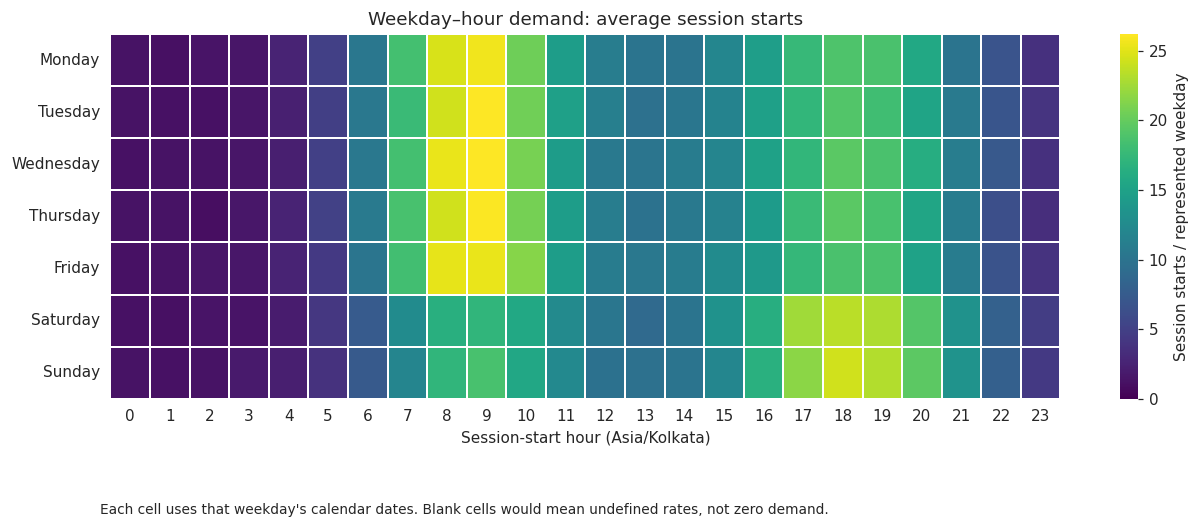

In [5]:
day_hour = tables["day_hour_demand"]
heatmap_values = day_hour.pivot(index="Weekday_Index", columns="Charging_Hour",
                               values="avg_sessions_per_day").reindex(index=range(7), columns=range(24))
fig, ax = plt.subplots(figsize=(12, 5))
sns.heatmap(heatmap_values, cmap="viridis", vmin=0,
            vmax=max(1, heatmap_values.max().max()), linewidths=0.3, ax=ax,
            cbar_kws={"label": "Session starts / represented weekday"})
ax.set_yticklabels(WEEKDAYS, rotation=0)
ax.set_ylabel("")
ax.set_xlabel("Session-start hour (Asia/Kolkata)")
ax.set_title("Weekday–hour demand: average session starts")
show_inline(fig, "Each cell uses that weekday's calendar dates. Blank cells would mean undefined rates, not zero demand.")

**Findings and limitations:** Weekday–hour rates range from 1.01 at Thursday 02:00 to 26.19 at Tuesday 09:00. Higher starts do not measure simultaneous occupancy or prove congestion.

## 5. Monthly demand

**Question:** How do calendar-normalized starts compare across year-months? **Metric:** starts/represented day, keeping each year-month separate. Asterisks and hatching identify partial boundary-month coverage; they do not mean missing measurements.

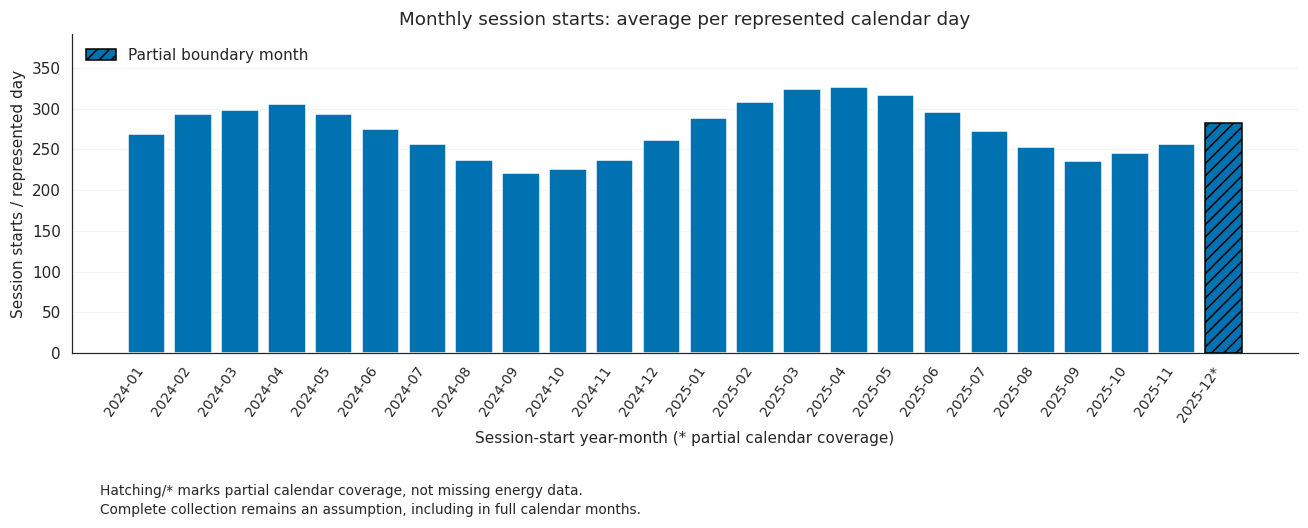

In [6]:
monthly = tables["monthly_demand"]
fig, ax = plt.subplots(figsize=(12, 5))
bars = ax.bar(range(len(monthly)), monthly.avg_sessions_per_day, color=BLUE)
for bar, is_partial in zip(bars, monthly.is_partial_boundary_month):
    if is_partial:
        bar.set_hatch("///")
        bar.set_edgecolor("black")
month_ticks(ax, monthly)
style_axis(ax, "Session starts / represented day")
ax.set_ylim(0, monthly.avg_sessions_per_day.max() * 1.2)
ax.set_title("Monthly session starts: average per represented calendar day")
ax.legend(handles=[Patch(facecolor=BLUE, edgecolor="black", hatch="///",
                          label="Partial boundary month")], frameon=False, loc="upper left")
show_inline(fig, "Hatching/* marks partial calendar coverage, not missing energy data.\nComplete collection remains an assumption, including in full calendar months.")

**Findings and limitations:** Monthly starts/day range from 220.93 in 2024-09 to 326.17 in 2025-04. Partial boundary months: 2025-12. Partial coverage is not a missing-data marker; the synthetic differences do not establish real seasonality or a causal trend.

## 6. Recorded energy associated with session-start periods

**Question:** How does recorded energy associated with starts vary by hour and month? **Metric:** valid recorded energy (kWh) per represented calendar day. Baseline retains all finite nonnegative measurements, including zero. Missing/invalid energy is not converted to zero or allowed to remove demand rows.

Whole session energy is assigned to its start period, even for cross-day/month sessions. These are not measured hourly electricity-load profiles.

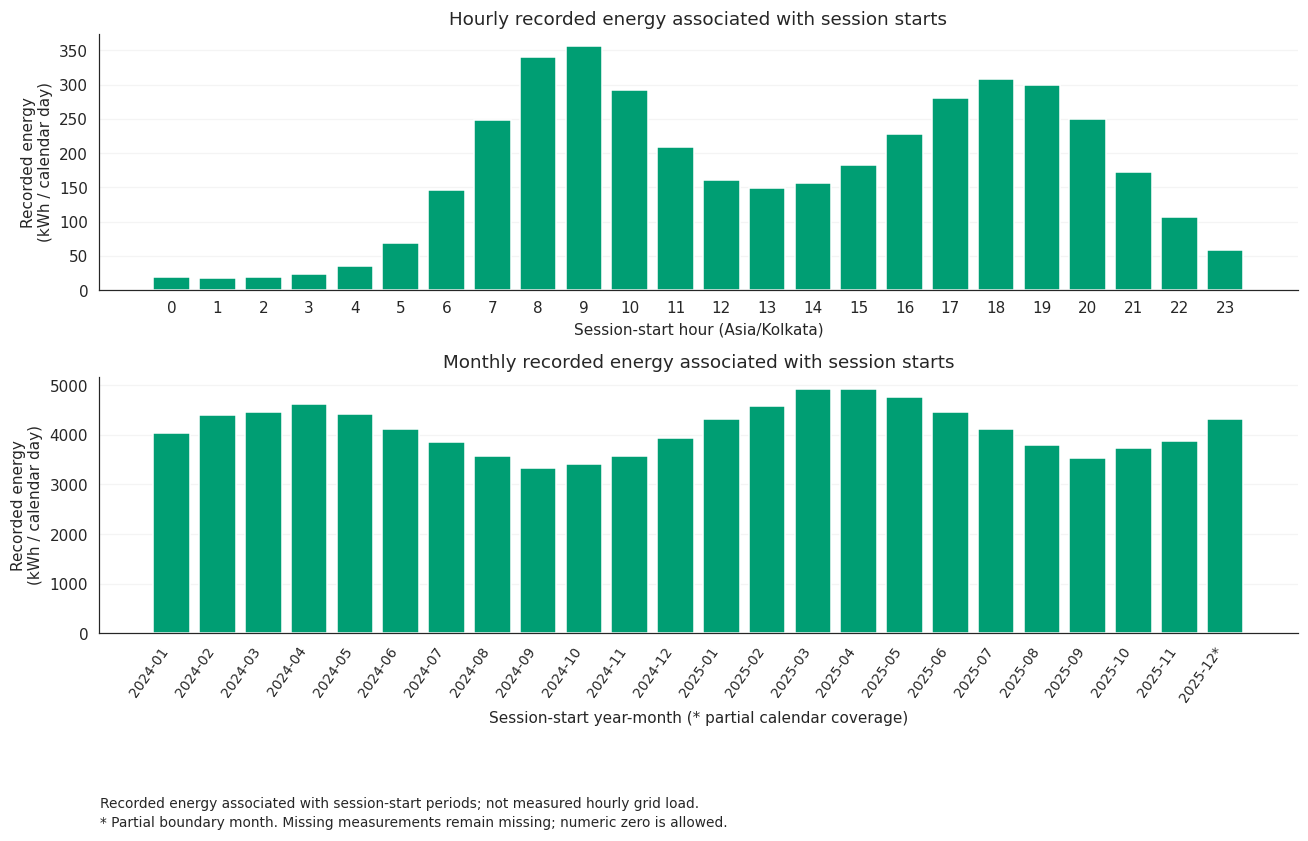

In [7]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8))
axes[0].bar(hourly.Charging_Hour, hourly.avg_recorded_energy_per_day_kwh, color=GREEN)
axes[0].set_xticks(range(24))
axes[0].set_xlabel("Session-start hour (Asia/Kolkata)")
axes[0].set_title("Hourly recorded energy associated with session starts")
axes[1].bar(range(len(monthly)), monthly.avg_recorded_energy_per_day_kwh, color=GREEN)
month_ticks(axes[1], monthly)
axes[1].set_title("Monthly recorded energy associated with session starts")
for ax in axes:
    style_axis(ax, "Recorded energy\n(kWh / calendar day)")
show_inline(fig, ENERGY_NOTE + "\n* Partial boundary month. Missing measurements remain missing; numeric zero is allowed.")

**Findings and limitations:** All 200,000 energy measurements are numerically valid: 3,014,172.81 kWh total, 15.07 kWh per valid-energy session. Monthly energy/day ranges from 3,327.97 kWh in 2024-09 to 4,929.07 kWh in 2025-04. Full energy belongs to the session-start period, not measured hourly grid load.

## 7. Energy plausibility validation

Both flags have zero true values in the supplied synthetic data. Report their counts rather than an uninformative comparison. Retained energy is 100% of baseline, not corrected or ground-truth data.

In [8]:
sensitivity = tables["monthly_energy_sensitivity"]
flag_counts = pd.DataFrame.from_dict(summary["input_validation"]["plausibility_flags"], orient="index")
display(flag_counts)
print("Union excluded:", summary["input_validation"]["plausibility_union_count"])
if sensitivity_has_variation(sensitivity):
    from src.demand_visualization import plot_sensitivity
    figure = plot_sensitivity(sensitivity)
    try:
        display(figure)
    finally:
        plt.close(figure)
else:
    print("No retained/excluded plausibility contrast: validation result reported instead of a comparison chart.")

,true,false,not_evaluable
Energy_Exceeds_Battery_Capacity,0,200000,0
Energy_Exceeds_Nominal_Charger_Energy,0,200000,0


Union excluded: 0
No retained/excluded plausibility contrast: validation result reported instead of a comparison chart.


**Validation result:** Zero flags, zero exclusions. This checks the supplied synthetic constraints without proving real equipment/measurement accuracy.

## Location-type hourly profiles

**Question and metric:** Which start hours dominate within each site category? The percentage denominator is all sessions in that location type, so each represented type sums to 100%; this compares profile shape rather than raw site volumes.

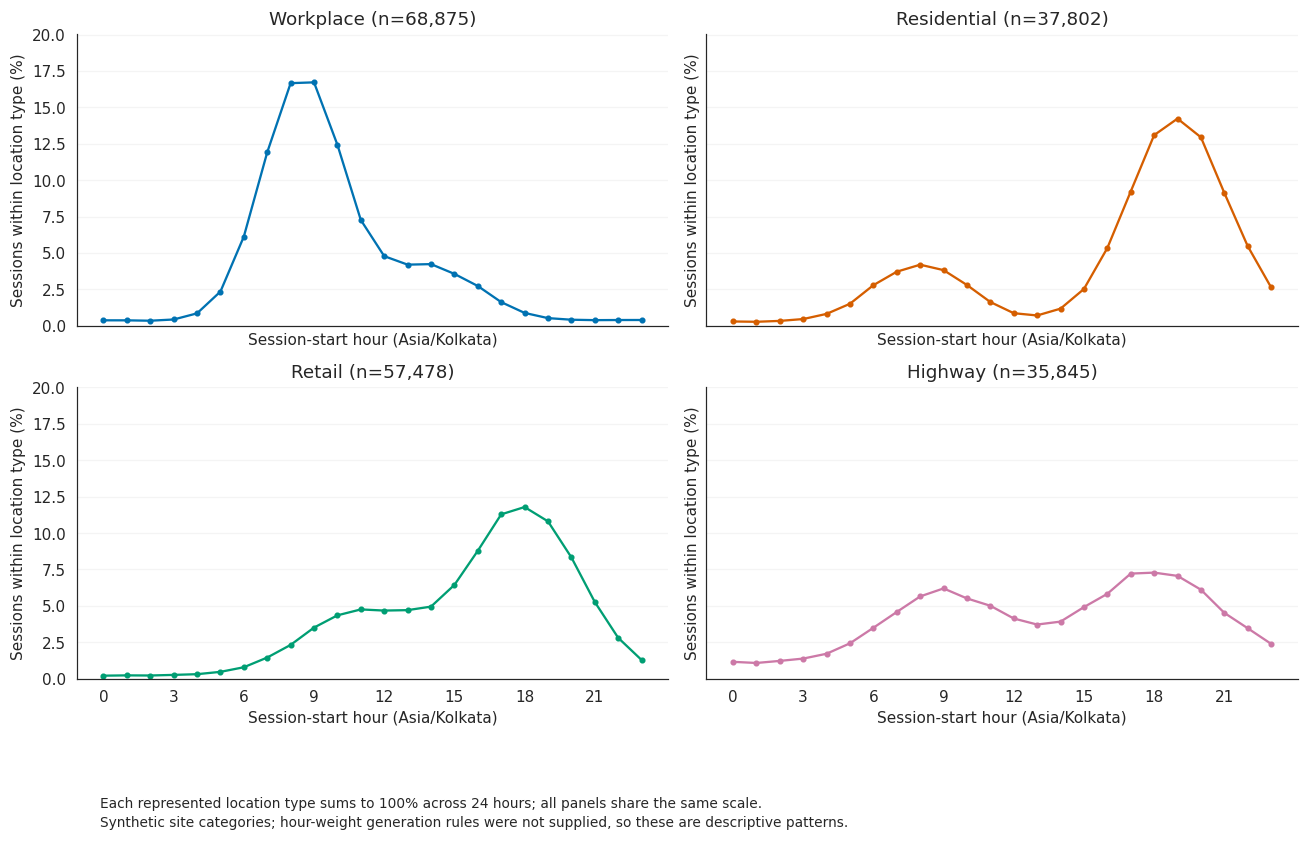

In [9]:
table = tables["location_type_hourly"]
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True, sharey=True)
colors = [BLUE, ORANGE, GREEN, "#CC79A7"]
ceiling = max(1, table.session_percentage.max() * 1.2)
for ax, location, color in zip(axes.flat, LOCATION_TYPES, colors):
    subset = table.loc[table.Location_Type.eq(location)]
    count = int(subset.location_session_count.iloc[0])
    ax.plot(subset.Charging_Hour, subset.session_percentage, color=color, marker="o", markersize=3)
    ax.set_title(f"{location} (n={count:,})")
    ax.set_xticks(range(0, 24, 3))
    ax.set_xlabel("Session-start hour (Asia/Kolkata)")
    style_axis(ax, "Sessions within location type (%)")
    ax.set_ylim(0, ceiling)
show_inline(fig, "Each represented location type sums to 100% across 24 hours; all panels share the same scale.\nSynthetic site categories; hour-weight generation rules were not supplied, so these are descriptive patterns.")

**Calculated findings:** Highway: 18:00, 7.28% (2,611/35,845 sessions); Residential: 19:00, 14.23% (5,378/37,802 sessions); Retail: 18:00, 11.79% (6,775/57,478 sessions); Workplace: 09:00, 16.72% (11,514/68,875 sessions).

**Interpretation and limitations:** Workplace/Residential/Retail/Highway are supplied synthetic site contexts. The morning Workplace and evening Residential/Retail peaks describe the CSV. Generator hourly weights were not provided, so no exact generation probabilities, real commuting behavior or causes are asserted.

## Weekday variability

**Question and metric:** How spread out are daily counts within each weekday? Use the existing full daily calendar, including zero-session dates. Boxes show linear-interpolated quartiles and median; whiskers extend to observations within 1.5 IQR.

,Weekday_Name,represented_days,q1_sessions,median_sessions,q3_sessions
0,Monday,105,247.00,277.0,307.00
1,Tuesday,105,253.00,278.0,296.00
2,Wednesday,104,252.75,277.0,308.25
3,Thursday,104,249.50,278.5,300.25
4,Friday,104,250.00,277.0,303.25
5,Saturday,104,237.00,266.5,291.25
6,Sunday,104,244.75,264.0,288.00


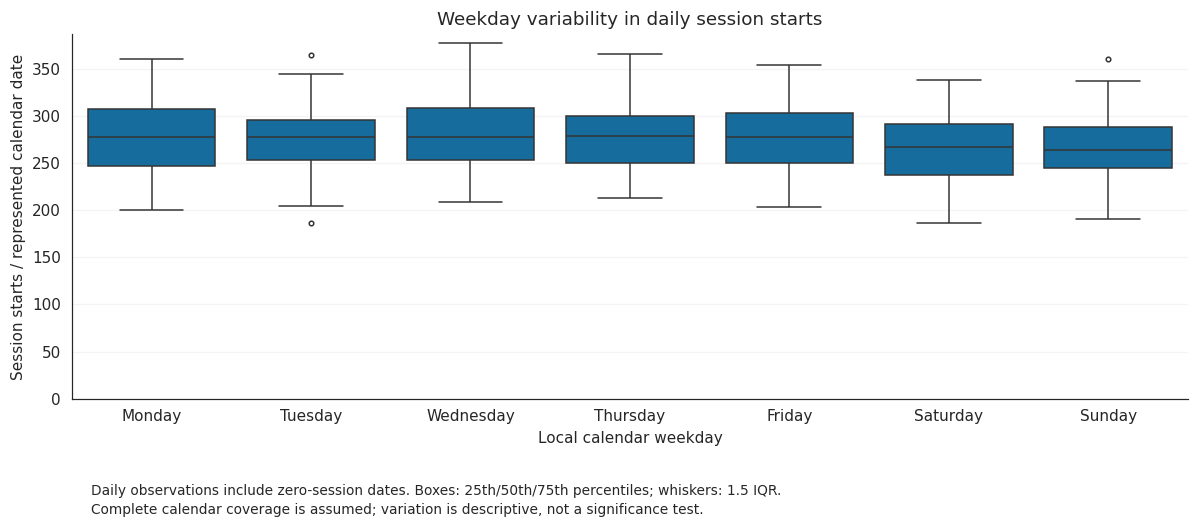

In [10]:
table = tables["daily_weekday_counts"]
display(tables["weekday_variability"][["Weekday_Name", "represented_days", "q1_sessions", "median_sessions", "q3_sessions"]].round(2))
fig, ax = plt.subplots(figsize=(11, 5))
sns.boxplot(data=table, x="Weekday_Name", y="session_count", order=WEEKDAYS,
            color=BLUE, ax=ax, fliersize=3)
ax.set_title("Weekday variability in daily session starts")
ax.set_xlabel("Local calendar weekday")
style_axis(ax, "Session starts / represented calendar date")
show_inline(fig, "Daily observations include zero-session dates. Boxes: 25th/50th/75th percentiles; whiskers: 1.5 IQR.\nComplete calendar coverage is assumed; variation is descriptive, not a significance test.")

**Calculated findings:** Daily medians: Monday 277, Tuesday 278, Wednesday 277, Thursday 278.5, Friday 277, Saturday 266.5, Sunday 264. Monday and Tuesday each have 105 represented dates; other weekdays have 104. Quartiles and counts are in weekday_variability.csv; zero dates are retained.

**Interpretation and limitations:** Calendar normalization removes unequal weekday representation; the boxplot exposes day-to-day spread rather than only group averages. Complete collection over the range is assumed, not measured uptime; no significance test is claimed.

## Time-period energy per session

**Question and metric:** Does energy per valid-energy session differ by start period? Non-overlapping local periods are Overnight [00,06), Morning [06,12), Afternoon [12,17), Evening [17,22), Late night [22,24). Whole energy is attributed to the start period, not grid load; unequal period lengths do not distort per-session averages.

,Time_Period,session_count,valid_energy_session_count,mean_energy_kwh,median_energy_kwh
0,Overnight,8855,8855,15.01,13.2
1,Morning,76931,76931,15.11,13.5
2,Afternoon,42513,42513,15.05,13.2
3,Evening,63634,63634,15.05,13.2
4,Late night,8067,8067,15.08,13.5


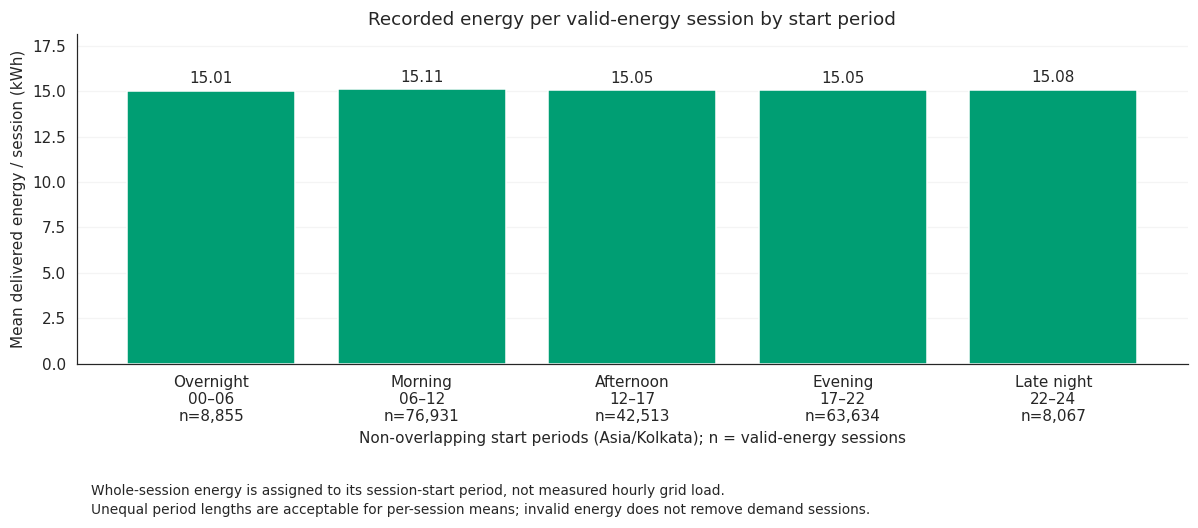

In [11]:
table = tables["time_period_energy"]
display(table[["Time_Period", "session_count", "valid_energy_session_count", "mean_energy_kwh", "median_energy_kwh"]].round(2))
fig, ax = plt.subplots(figsize=(11, 5))
labels = [f"{row.Time_Period}\n{row.start_hour_inclusive:02d}–{row.end_hour_exclusive:02d}\nn={row.valid_energy_session_count:,}"
          for row in table.itertuples()]
bars = ax.bar(labels, table.mean_energy_kwh, color=GREEN)
ax.bar_label(bars, fmt="%.2f", padding=3)
ax.set_ylim(0, max(1, table.mean_energy_kwh.max()) * 1.2)
ax.set_title("Recorded energy per valid-energy session by start period")
ax.set_xlabel("Non-overlapping start periods (Asia/Kolkata); n = valid-energy sessions")
style_axis(ax, "Mean delivered energy / session (kWh)")
show_inline(fig, "Whole-session energy is assigned to its session-start period, not measured hourly grid load.\nUnequal period lengths are acceptable for per-session means; invalid energy does not remove demand sessions.")

**Calculated findings:** Mean/median kWh per valid-energy session: Overnight 15.01/13.20 (n=8,855); Morning 15.11/13.50 (n=76,931); Afternoon 15.05/13.20 (n=42,513); Evening 15.05/13.20 (n=63,634); Late night 15.08/13.50 (n=8,067).

**Interpretation and limitations:** Similar per-session energies coexist with different period session volumes. The simulation contract ties energy to battery/SOC quantities and active-power limits, not to our chart period labels. No time-of-day energy relationship was imposed by this analysis.

## Charger-type comparison

**Question and metric:** How do AC Slow, AC Fast and DC Fast differ? Energy (kWh), active duration (Charging_End minus start) and connected occupancy (Session_End minus start) are separate panels. Calculations check supplied duration fields and keep invalid energy out of energy metrics only.

,Charger_Type,session_count,mean_energy_kwh,median_energy_kwh,mean_active_charging_duration_min,mean_connected_duration_min
0,AC Slow,28764,15.07,13.2,274.19,352.48
1,AC Fast,94977,15.09,13.2,80.53,146.39
2,DC Fast,76259,15.05,13.2,29.76,48.23


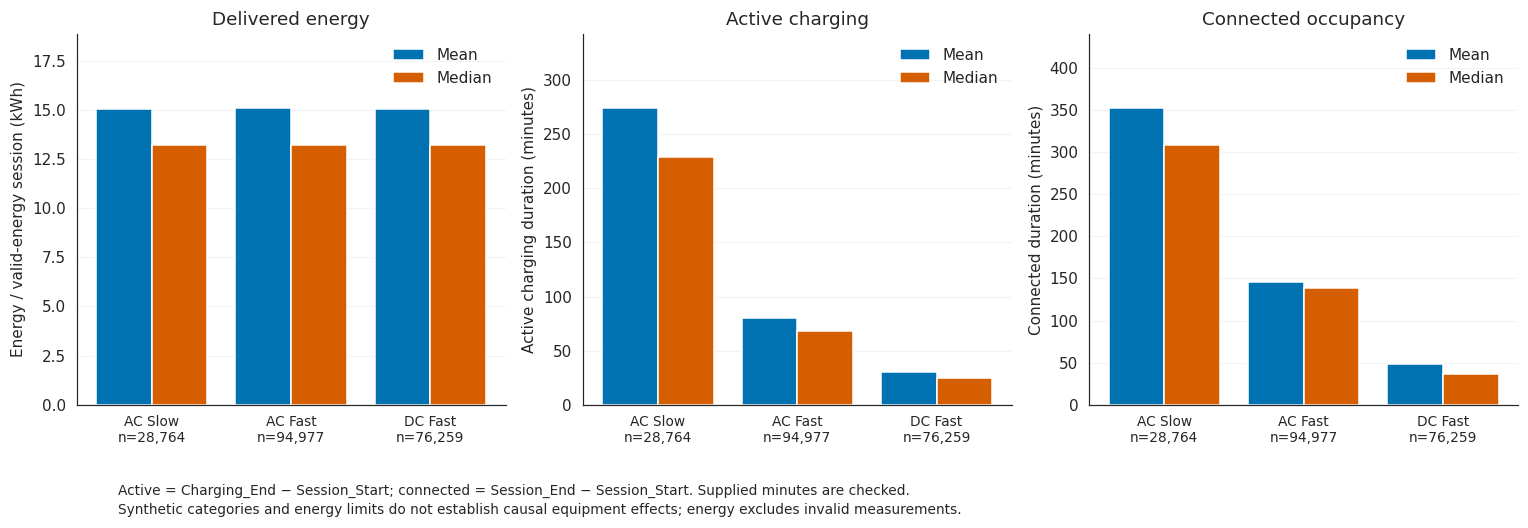

In [12]:
table = tables["charger_type_comparison"]
display(table[["Charger_Type", "session_count", "mean_energy_kwh", "median_energy_kwh", "mean_active_charging_duration_min", "mean_connected_duration_min"]].round(2))
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
x = pd.Series(range(len(table)))
labels = [f"{row.Charger_Type}\nn={row.session_count:,}" for row in table.itertuples()]
for ax, mean, median, title, units in [
    (axes[0], "mean_energy_kwh", "median_energy_kwh", "Delivered energy", "Energy / valid-energy session (kWh)"),
    (axes[1], "mean_active_charging_duration_min", "median_active_charging_duration_min", "Active charging", "Active charging duration (minutes)"),
    (axes[2], "mean_connected_duration_min", "median_connected_duration_min", "Connected occupancy", "Connected duration (minutes)"),
]:
    ax.bar(x - 0.2, table[mean], width=0.4, color=BLUE, label="Mean")
    ax.bar(x + 0.2, table[median], width=0.4, color=ORANGE, label="Median")
    ax.set_xticks(x, labels, fontsize=9)
    ax.set_title(title)
    style_axis(ax, units)
    ax.set_ylim(0, max(1, table[[mean, median]].max().max()) * 1.25)
    ax.legend(frameon=False)
show_inline(fig, "Active = Charging_End − Session_Start; connected = Session_End − Session_Start. Supplied minutes are checked.\nSynthetic categories and energy limits do not establish causal equipment effects; energy excludes invalid measurements.")

**Calculated findings:** AC Slow: n=28,764, mean energy 15.07 kWh, mean active 274.19 min, mean connected 352.48 min; AC Fast: n=94,977, mean energy 15.09 kWh, mean active 80.53 min, mean connected 146.39 min; DC Fast: n=76,259, mean energy 15.05 kWh, mean active 29.76 min, mean connected 48.23 min. Supplied active/connected duration mismatch counts are zero.

**Interpretation and limitations:** The documented synthetic contract separates active charging from post-charge occupancy and bounds energy by nominal power times active hours. Shorter DC Fast active times are consistent with that contract; similar energy means do not imply a causal charger effect or identical vehicle/sample composition.

## Handoff


The input is generated synthetic Indian charging data. Station mappings are internally consistent in this run, not independently verified locations. Generator code, seed, distribution/efficiency assumptions and reuse licence were not supplied. Keep arrivals, active charging and port occupancy separate. Counts alone do not prove congestion; port counts do not establish operational availability. Refresh Power BI fields and port/active duration measures as described in docs/dataset_migration.md. Keep the session-level date table and matching-filter checks.

In [13]:
assert protected_hashes == {path: file_hash(path) for path in protected}
assert not plt.get_fignums(), "Close every figure after its inline display."
print("Inputs and verified summaries unchanged. Ten inline figures displayed for the current data; none saved or loaded from image files.")

Inputs and verified summaries unchanged. Ten inline figures displayed for the current data; none saved or loaded from image files.
